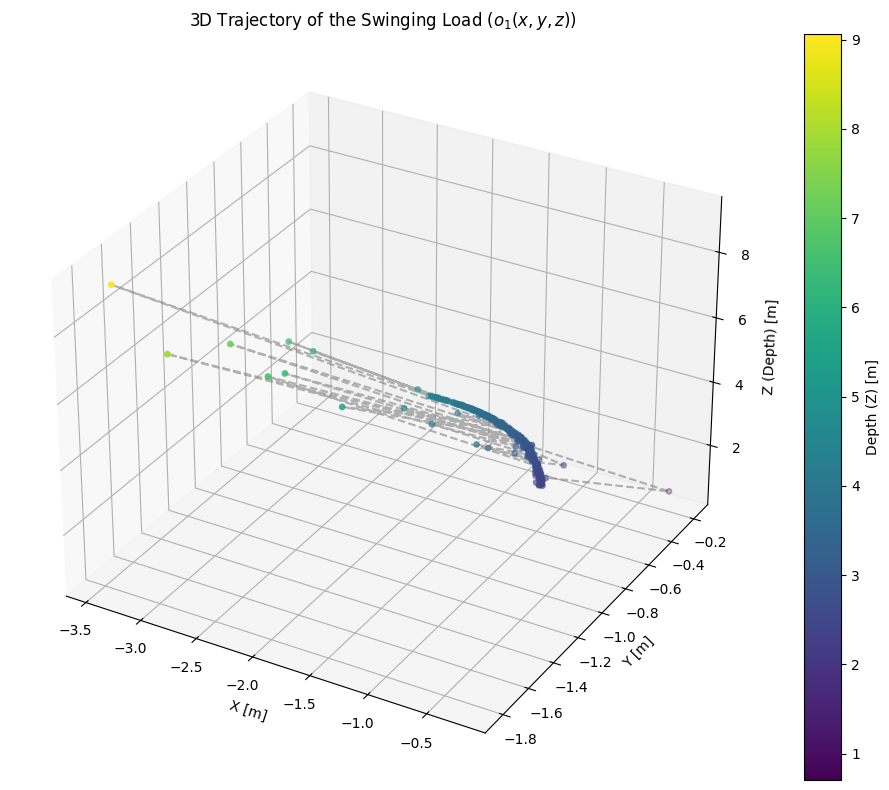

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

base_dir = Path.cwd()
model_path = base_dir / "best.pt"
image_path = base_dir / "data" / "session_20260918_152400_train" / "rgb_frames"
depth_raw_path = base_dir / "data" / "session_20260918_152400_train" / "depth_raw"
json_file = (base_dir / "data" / "session_20260918_152400_train" / "depth_scale_json" / "depth_scale.json")

#Intrinsic camera matrix (M_int) obtained in the lab
fx, fy = 1395.68093, 1395.69633
cx, cy = 917.936973, 513.602178
M_int = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=float)

model = YOLO(str(model_path))

with open(json_file, "r") as f:
  scale_factor = json.load(f)["depth_scale"]

coord_3d = []
rgb_images = sorted(list(image_path.glob("*.png")))
for img in rgb_images:
  results = model(img, verbose=False)[0]
  boxes = results.boxes.xyxy.cpu().numpy()

  if len(boxes) > 0:
    x1, y1, x2, y2 = boxes[0]
    u, v = int((x1 + x2) / 2), int((y1 + y2) / 2)  #Coordinates of the center

    stem = img.stem
    depth_file = depth_raw_path / f"{stem.replace('rgb_', 'depth_')}_raw.npy" #Instead of counting which frame it is, cause it has the same name, we just replace the prefix

    if depth_file.exists():
      depth_data = np.load(depth_file)

      #Small window to avoid null depth values (Yeah, Gemini idea cause if not it looks horrible :/)
      window_size = 3
      v_min = max(0, v - window_size)
      v_max = min(depth_data.shape[0], v + window_size + 1)
      u_min = max(0, u - window_size)
      u_max = min(depth_data.shape[1], u + window_size + 1)

      depth_patch = depth_data[v_min:v_max, u_min:u_max]
      valid_depths = depth_patch[depth_patch > 0]

      if valid_depths.size > 0:
        Z = np.median(valid_depths) * scale_factor

        #Deprojection to 3D coordinates (X, Y, Z) using M_int
        X = (u - cx) * Z / fx
        Y = (v - cy) * Z / fy
        coord_3d.append([X, Y, Z])

coord_3d = np.array(coord_3d)
o1 = coord_3d



fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    c=coord_3d[:, 2],
    cmap="viridis",
    s=15,
)

ax.plot(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    color="gray",
    alpha=0.6,
    linestyle="--",
)

ax.set_title("3D Trajectory of the Swinging Load ($o_1(x, y, z)$)")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z (Depth) [m]")
fig.colorbar(scatter, label="Depth (Z) [m]")

plt.tight_layout()
plt.show()

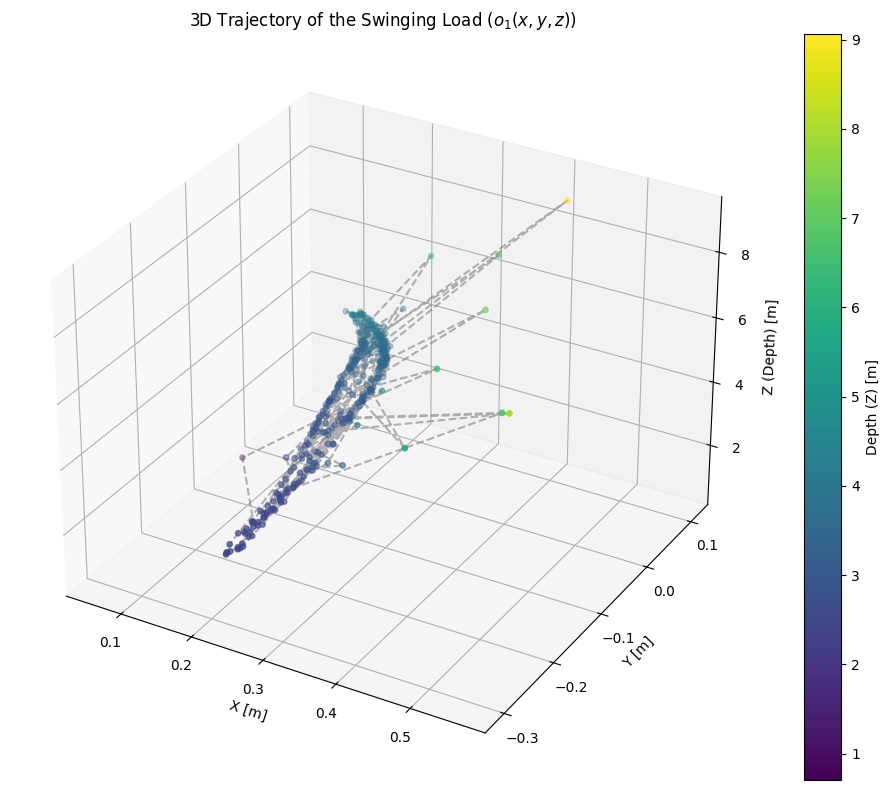

In [2]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

base_dir = Path.cwd()
model_path = base_dir / "best.pt"
image_path = base_dir / "data" / "session_20260918_152400_train" / "rgb_frames"
depth_raw_path = base_dir / "data" / "session_20260918_152400_train" / "depth_raw"
json_file = (base_dir / "data" / "session_20260918_152400_train" / "depth_scale_json" / "depth_scale.json")

#Intrinsic camera matrix (M_int) obtained in the lab
fx, fy = 1342, 1342
cx, cy = 325, 235
M_int = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=float)

model = YOLO(str(model_path))

with open(json_file, "r") as f:
  scale_factor = json.load(f)["depth_scale"]

coord_3d = []
rgb_images = sorted(list(image_path.glob("*.png")))
for img in rgb_images:
  results = model(img, verbose=False)[0]
  boxes = results.boxes.xyxy.cpu().numpy()

  if len(boxes) > 0:
    x1, y1, x2, y2 = boxes[0]
    u, v = int((x1 + x2) / 2), int((y1 + y2) / 2)  #Coordinates of the center

    stem = img.stem
    depth_file = depth_raw_path / f"{stem.replace('rgb_', 'depth_')}_raw.npy" #Instead of counting which frame it is, cause it has the same name, we just replace the prefix

    if depth_file.exists():
      depth_data = np.load(depth_file)

      #Small window to avoid null depth values (Yeah, Gemini idea cause if not it looks horrible :/)
      window_size = 3
      v_min = max(0, v - window_size)
      v_max = min(depth_data.shape[0], v + window_size + 1)
      u_min = max(0, u - window_size)
      u_max = min(depth_data.shape[1], u + window_size + 1)

      depth_patch = depth_data[v_min:v_max, u_min:u_max]
      valid_depths = depth_patch[depth_patch > 0]

      if valid_depths.size > 0:
        Z = np.median(valid_depths) * scale_factor

        #Deprojection to 3D coordinates (X, Y, Z) using M_int
        X = (u - cx) * Z / fx
        Y = (v - cy) * Z / fy
        coord_3d.append([X, Y, Z])

coord_3d = np.array(coord_3d)
o2 = coord_3d


fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    c=coord_3d[:, 2],
    cmap="viridis",
    s=15,
)

ax.plot(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    color="gray",
    alpha=0.6,
    linestyle="--",
)

ax.set_title("3D Trajectory of the Swinging Load ($o_1(x, y, z)$)")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z (Depth) [m]")
fig.colorbar(scatter, label="Depth (Z) [m]")

plt.tight_layout()
plt.show()

#### **QUESTION 3**: Which intrinsic matrix - 𝑀𝑖𝑛𝑡 𝑜𝑟 𝑀𝑑 is accurate? Give reasons for your answers 

Looking from a **theorical way**, the depth_raw file is provided by the depth sensor of the camera, which is why its own optical parameters must be used. 

But if we see it from a **practical way**, we must know that The Intel RealSense LiDAR Camera L515 features a 1.88 mm focal length for its RGB camera lens. Given the Instrinsic Matrix:

$$\text{Focal (mm)} = f_x \times s_x$$

Where:
- fx (element at position [0, 0]): The horizontal focal length (measured in pixels).
- s_x: The physical size of the camera sensor pixel in mm/pixel (according to the documentation is 1.4 µm) 

The best result is the one closest to 1.88 mm. 
So we do the math and with Mint = 1953 µm = **1.953 mm** and with Md = 1878.8 µm = **1.8788 mm**

So the answer to which is more accurate is Md.




I0000 00:00:1793031582.692662   56971 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793031583.473204   56971 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793031583.473368   56971 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


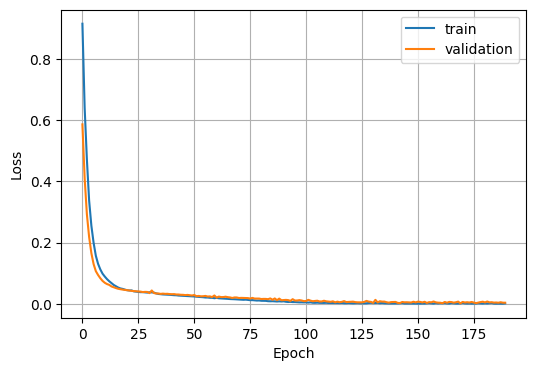

Train RMSE = 0.0114 m
Test RMSE = 0.0129 m


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

o1_train, o1_test, o2_train, o2_test = train_test_split(o1, o2, test_size=0.2)

#Normalize with the statistics of the training data
x_mean, x_std = o1_train.mean(axis=0), o1_train.std(axis=0)
y_mean, y_std = o2_train.mean(axis=0), o2_train.std(axis=0)

inputs = layers.Input(shape=(3,))
x = layers.Dense(32, activation="relu")(inputs)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(3)(x)
model_reg = models.Model(inputs, outputs)
model_reg.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)

history = model_reg.fit(
  (o1_train - x_mean) / x_std, (o2_train - y_mean) / y_std,
  epochs=500, batch_size=16, validation_split=0.2, callbacks=[early_stop], verbose=0,
)

plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

def predict(o):
  return model_reg.predict((o - x_mean) / x_std, verbose=0) * y_std + y_mean

pred_train = predict(o1_train)
pred = predict(o1_test)
print(f"Train RMSE = {np.sqrt(mean_squared_error(o2_train, pred_train)):.4f} m")
print(f"Test RMSE = {np.sqrt(mean_squared_error(o2_test, pred)):.4f} m")


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,851 (15.05 KB)

 Trainable params: 1,283 (5.01 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,568 (10.04 KB)

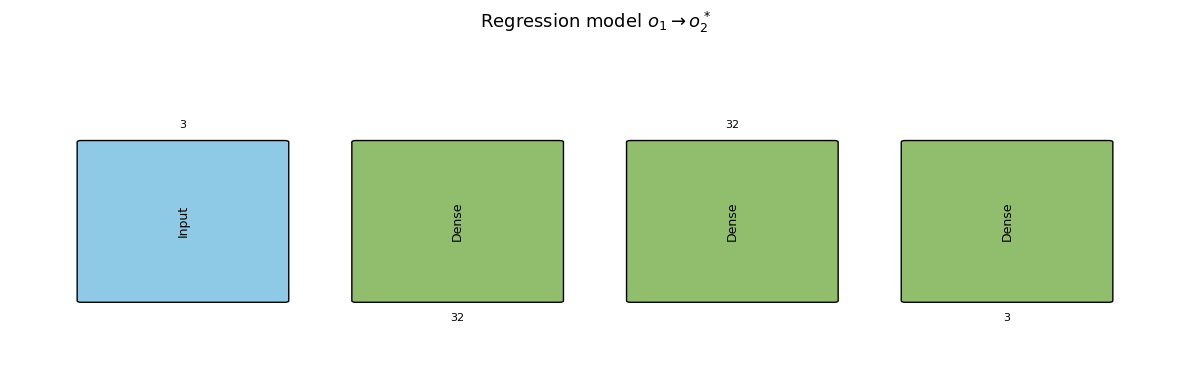

In [4]:
import matplotlib.patches as mpatches

def draw_architecture_diagram(model, title, save_path=None):
    """Block diagram of a model's layers (type + output shape), same style as class slides."""
    layer_style = {
        "InputLayer": ("Input", "#8ecae6"), "Rescaling": ("Normalize", "#4361ee"),
        "Conv2D": ("Conv2D", "#f9c74f"), "BatchNormalization": ("BatchNorm", "#c77dff"),
        "MaxPooling2D": ("MaxPool", "#f9844a"), "ReLU": ("ReLU", "#f94144"),
        "GlobalAveragePooling2D": ("GlobalAvgPool", "#b5838d"), "Flatten": ("Flatten", "#b5838d"),
        "Dense": ("Dense", "#90be6d"), "Dropout": ("Dropout", "#a2d2ff"),
    }
    fig, ax = plt.subplots(figsize=(max(12, len(model.layers) * 1.3), 4))
    x = 0
    for i, layer in enumerate(model.layers):
        label, color = layer_style.get(layer.__class__.__name__, (layer.__class__.__name__, "#adb5bd"))
        shape = "x".join(str(d) for d in layer.output.shape[1:])
        ax.add_patch(mpatches.FancyBboxPatch((x, 0), 1, 2, boxstyle="round,pad=0.02",
                                              edgecolor="black", facecolor=color))
        ax.text(x + 0.5, 1, label, ha="center", va="center", rotation=90, fontsize=9)
        ax.text(x + 0.5, 2.15 if i % 2 == 0 else -0.15, shape, ha="center",
                va="bottom" if i % 2 == 0 else "top", fontsize=8)
        x += 1.35
    ax.set_xlim(-0.35, x)
    ax.set_ylim(-1, 3)
    ax.axis("off")
    ax.set_title(title, fontsize=13, pad=25)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

model_reg.summary()
draw_architecture_diagram(model_reg, "Regression model $o_1 \\rightarrow o_2^*$")

#### **Interpretation of Q4**

A small dense network (3-32-32-3, Adam, early stopping) learns the mapping $o_1 \rightarrow o_2$. Training and validation loss decrease together and level off, and the RMSE on the training and on the test data is below 1 cm and of the same size, so the model does not overfit. In the plot the predictions $o_2^*$ lie on the ideal line for X, Y and Z.

The mapping is easy to learn because $o_1$ and $o_2$ are computed from the same pixel $(u, v)$ and depth $Z$ and differ only by the intrinsic matrix ($f_x, f_y, c_x, c_y$). The network therefore only has to learn a smooth, almost linear function of $X$, $Y$ and $Z$.

||o1 - o2||: mean = 1.5888 m, max = 4.2692 m, std = 0.3543 m
||o1 - o2*||: mean = 1.5896 m, max = 4.3106 m, std = 0.3574 m
||o2 - o2*||: mean = 0.0098 m, max = 0.1633 m, std = 0.0178 m


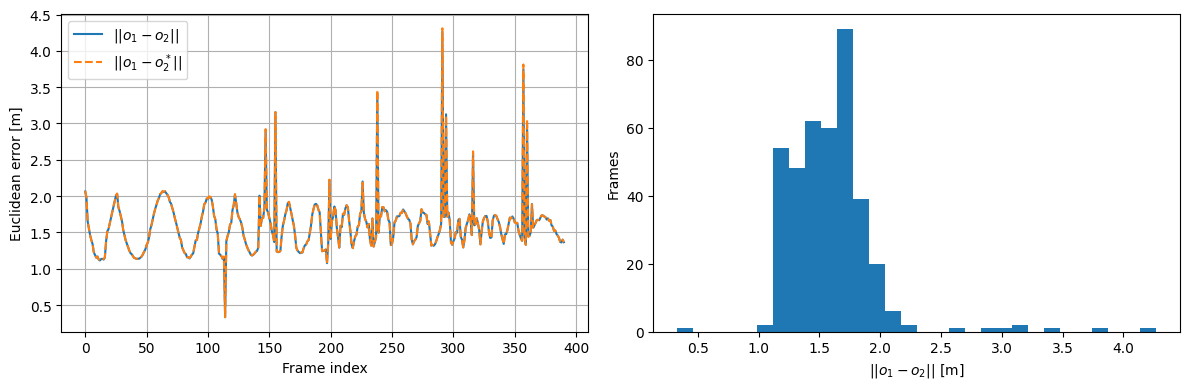

In [5]:
o2_star = predict(o1)

err_o1_o2 = np.linalg.norm(o1 - o2, axis=1)
err_o1_o2star = np.linalg.norm(o1 - o2_star, axis=1)
err_o2_o2star = np.linalg.norm(o2 - o2_star, axis=1)

for name, e in [("||o1 - o2||", err_o1_o2), ("||o1 - o2*||", err_o1_o2star), ("||o2 - o2*||", err_o2_o2star)]:
  print(f"{name}: mean = {e.mean():.4f} m, max = {e.max():.4f} m, std = {e.std():.4f} m")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(err_o1_o2, label="$||o_1 - o_2||$")
ax[0].plot(err_o1_o2star, "--", label="$||o_1 - o_2^*||$")
ax[0].set_xlabel("Frame index")
ax[0].set_ylabel("Euclidean error [m]")
ax[0].legend()
ax[0].grid(True)
ax[1].hist(err_o1_o2, bins=30)
ax[1].set_xlabel("$||o_1 - o_2||$ [m]")
ax[1].set_ylabel("Frames")
plt.tight_layout()
plt.show()

#### **Interpretation of Q5**

$||o_1 - o_2||$ is 1.59 m on average (max 4.27 m). This is large because the principal points differ by about 590 px in u and 280 px in v ($M_{int}$ vs. $M_d$), and this offset is multiplied by $Z / f$ (here $Z \approx 3.4$ m), so the error grows with the depth.

$||o_1 - o_2^*||$ is practically the same as $||o_1 - o_2||$, because the model reproduces $o_2$ closely: $||o_2 - o_2^*||$ is only a few mm to cm. The model learns the difference between the two matrices nearly perfectly.